<Axes: ylabel='word'>

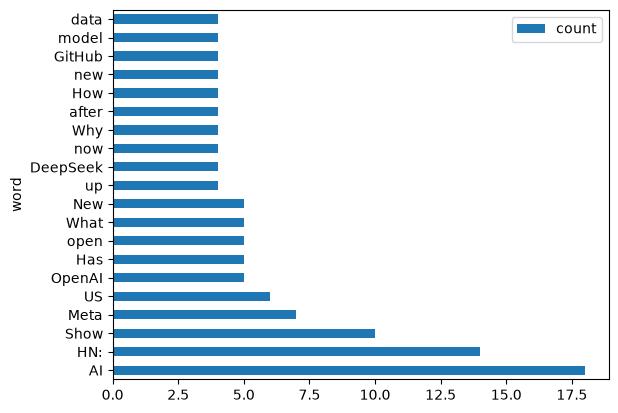

In [ ]:
import pyarrow
import pandas as pd
import matplotlib.pyplot as plt

# 1. Какие слова в заголовках чаще всего встречаются у самых популярных постов?

hn = pd.read_parquet("data/2026-08.parquet")

posts = hn[hn["type"] == 1]
sorted_by_score = posts.sort_values(by="score", ascending=False)
first_200 = sorted_by_score.head(200)

word_freq = pd.DataFrame({"word": [], "count": []})
for title in first_200["title"]:
    for word in str(title).split():
        index = word_freq.index[word_freq["word"] == word].to_list()
        
        if len(index) == 0:
            word_freq.loc[len(word_freq)] = [word, 1]
        else:
            word_freq.loc[index[0], "count"] += 1

exclude = ["to", "in", "a", "the", "and", "for", "of", "–", "on", "The", "Is", "is",
           "with", "by", "I", "at", "that", "as", "from", "than", "an", "does", "its",
           "are", "was"]
sorted_word_freq = word_freq.sort_values(by="count", ascending=False)
first_20 = sorted_word_freq[~sorted_word_freq["word"].isin(exclude)].head(20)

first_20.set_index("word").plot.barh()


<Axes: xlabel='time'>

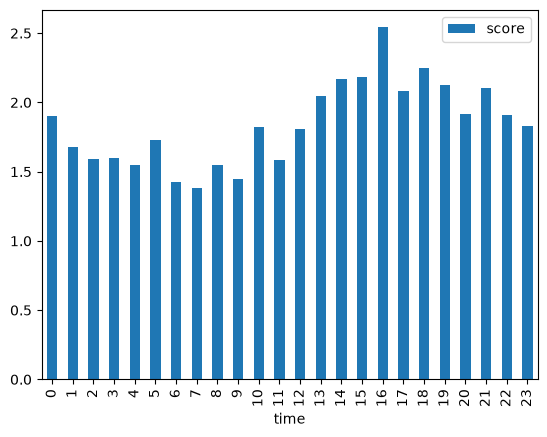

In [59]:
# 2. В какое время суток лучше публиковать пост, чтобы получить больше всего очков (upvotes)?
mean_score_by_time_of_day = posts.groupby(posts["time"].dt.hour)["score"].mean().to_frame()
mean_score_by_time_of_day.plot.bar()

<Axes: xlabel='score'>

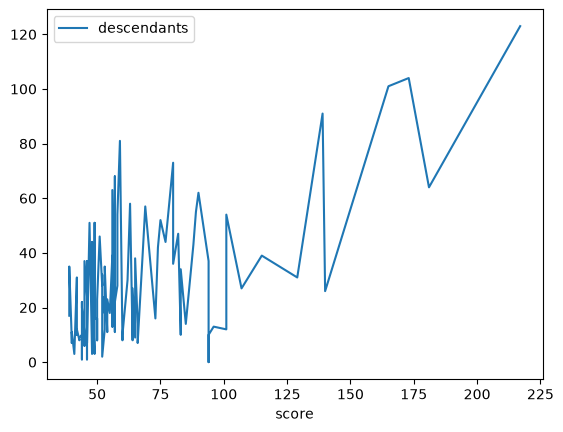

In [77]:
# 3. Влияет ли количество комментариев на рейтинг поста?
comments = posts[["score", "descendants"]].sort_values(by="score", ascending=False).head(100).set_index("score")
comments.plot()